# VloeiStof Showcase

VloeiStof is a 2D incompressible navier stokes solver developed in python, generalized for any grid domain. Using a finite difference framework, VloeiStof achieves it's speed through array vectorization and a standard scientific tech-stack of numpy and scipy functionalities. 

The selling point of VloeiStof is rapid prototyping. Things like microfluidic devices, chamber and pipe flow, or any other funky stuff you want to try out but don't want to commit a massive amount of time or compute to. Here are some examples of how to use it, and what you can do with it! 

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm

# import NavierStokesSolver to use VloeiStof
from fluids.navier import NavierStokesSolver

# Showcase: Flow through a microfluidic device 

Microfluidic devices are super small little devices and chambers used to manipulate small volumes of fluid. Imagine we are trying to solve for the flow of one that looks like this image below. Under continuous use, the flow through this device will eventually (should do at least) steady state... what does that look like?

![title](../images/microfluidic_device.png)

We start with creating out problem we, creating meshes of the pressure field we are expecting (a differential of 0.01 Pa), the size of the domains, defining the boundaries and fluid characteristics, etc. 

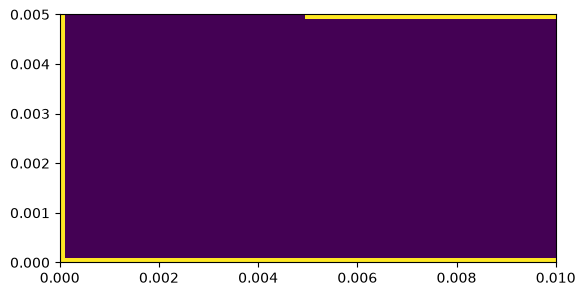

In [35]:
# physical parameters
rho = 1000  # kgm^-3
nu = 0.001 / rho  # Pa s / kgm^-3

Lx, Ly = 0.01, 0.005  # m

Pmax = 0.01  # Pa

Nx, Ny = 101, 51

dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

X, Y = np.mgrid[0:Nx:1, 0:Ny:1]
X = X * dx
Y = Y * dy

# initial flow set at rest
u = np.zeros_like(X)
v = np.zeros_like(X)

# initialize pressure field
p = np.zeros_like(X)
p[: Nx // 2, -1] = Pmax
p[-1, :] = 0.0

# define the boundary mesh, 1s are walls, 0s are fluid cells
boundary_mesh = np.zeros_like(X, dtype=bool)
boundary_mesh[: Nx // 2, -1] = False
boundary_mesh[-1, :] = False
boundary_mesh[0, :] = True
boundary_mesh[:, 0] = True
boundary_mesh[Nx // 2 :, -1] = True

# look at the boundary mesh
plt.imshow(
    boundary_mesh.T,
    origin="lower",
    extent=[X[0, 0], X[-1, -1], Y[0, 0], Y[-1, -1]],
    aspect="equal",
)

Now we give all that information to VloeiStof to create a NavierStokesSolver object that will take care of the entire simulation for us, nice and easy right?

In [36]:
solver = NavierStokesSolver(
    boundary_mesh=boundary_mesh,
    Pmax=Pmax,
    p=p,
    u=u,
    v=v,
    nu=nu,
    rho=rho,
    Lx=Lx,
    Ly=Ly,
    Nx=Nx,
    Ny=Ny,
)

Now just sit back and relax for around 20 seconds while the simulation runs...

In [37]:
u, v, p = solver.solve_NS(t_end=15)

Flow achieved steady state at t = 11.85s
velocity residual = 1.3364306173466393e-07
norm(u) = 0.11453221, norm(v) = 0.06927270
Courant number: 0.00626776


Lets have a look at the solution now:

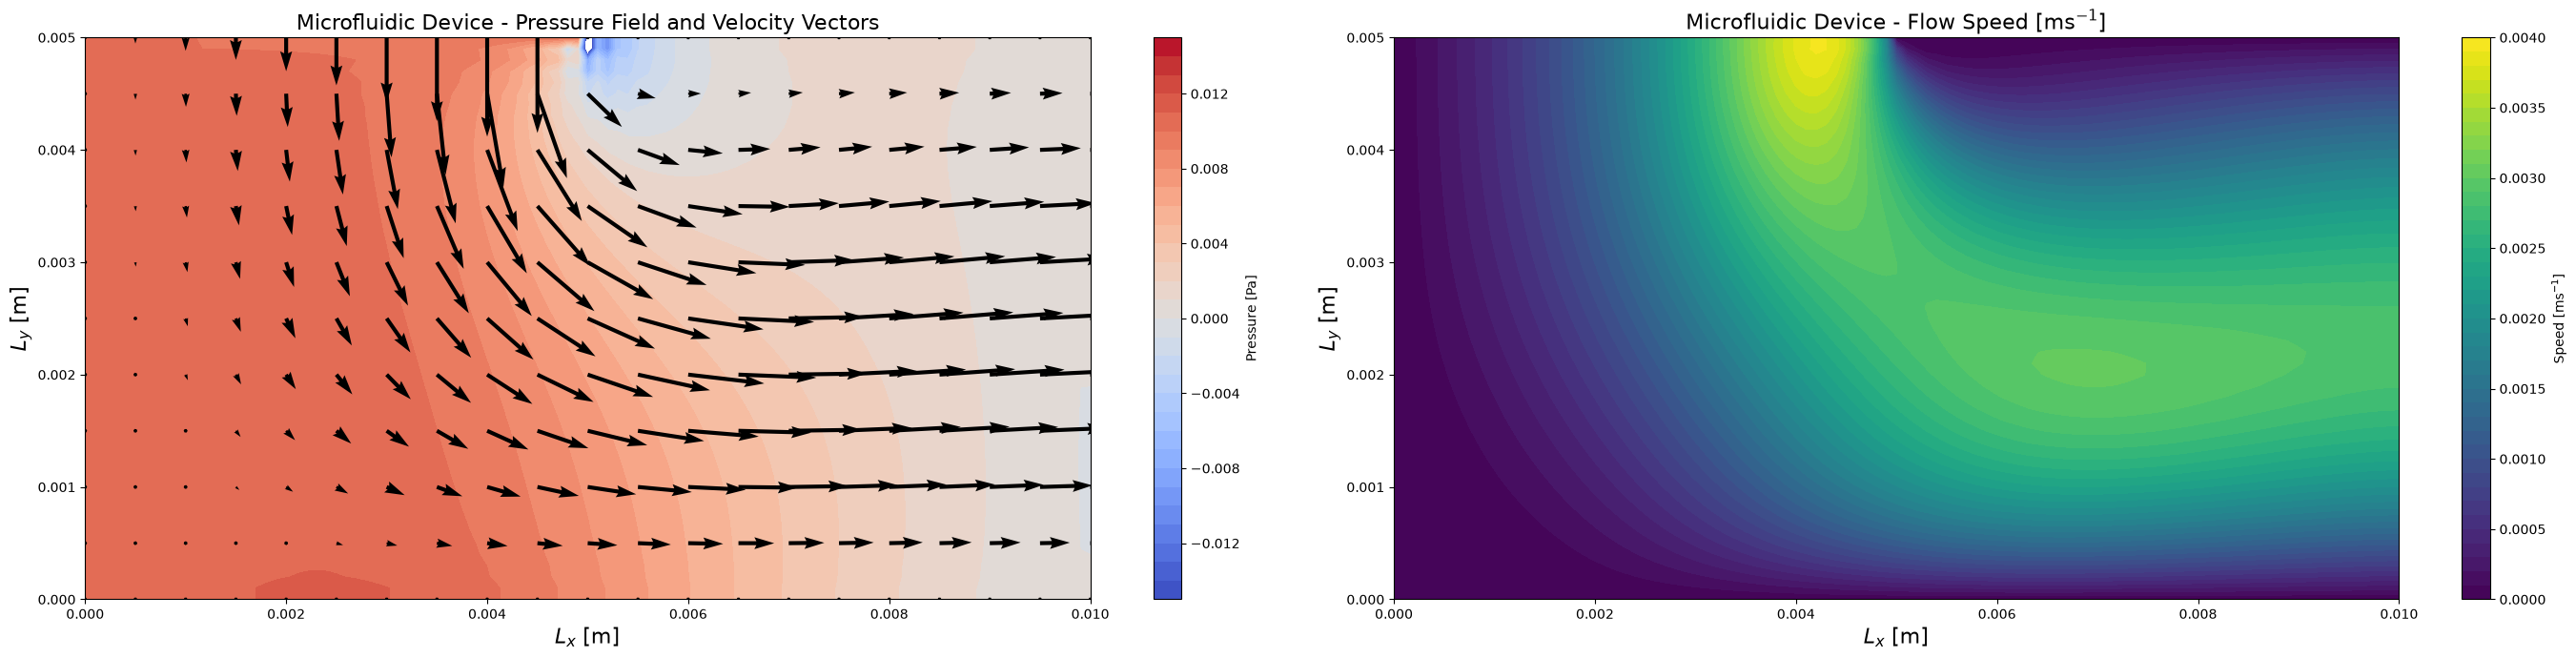

In [38]:
# set up figure
fig = plt.figure(figsize=(28, 7))
ax1 = fig.add_subplot(121)
cont = ax1.contourf(
    X, Y, p, cmap=cm.coolwarm, levels=np.arange(-0.015, 0.015 + 0.001, 0.001)
)
fig.colorbar(cont, label="Pressure [Pa]")

ax1.quiver(X[::5, ::5], Y[::5, ::5], u[::5, ::5], v[::5, ::5])
ax1.set_xlabel("$L_x$ [m]", fontsize=16)
ax1.set_ylabel("$L_y$ [m]", fontsize=16)
ax1.set_title("Microfluidic Device - Pressure Field and Velocity Vectors", fontsize=16)

ax1 = fig.add_subplot(122)
cont = ax1.contourf(
    X,
    Y,
    np.sqrt(u * u + v * v),
    cmap=cm.viridis,
    levels=np.arange(0, 0.004 + 0.0001, 0.0001),
)
fig.colorbar(cont, label="Speed [ms$^{-1}$]")
ax1.set_xlabel("$L_x$ [m]", fontsize=16)
ax1.set_ylabel("$L_y$ [m]", fontsize=16)
ax1.set_title("Microfluidic Device - Flow Speed [ms$^{-1}$]", fontsize=16)

plt.tight_layout()

To test the accuracy, we can do some basic analysis. Let's have a look at the flowrates across the inlet and outlets, given its steady state incompressible... should be the same? 

In [ ]:
flowrate_inlet = np.trapezoid(np.abs(v[: Nx // 2, -1]), dx=dx)
print(f"Average Flowrate (Inlet): {flowrate_inlet:.6e} m^2/s")

flowrate_outlet = np.trapezoid(u[-1, :], dx=dy)
print(f"Average Flowrate (Outlet): {flowrate_outlet:.6e} m^2/s")

error = np.abs(flowrate_inlet - flowrate_outlet) / flowrate_inlet * 100
print(
    f"Error in flowrate: {error:.3}%"
)

Average Flowrate (Inlet): 9.285188e-06 m^2/s
Average Flowrate (Outlet): 9.398965e-06 m^2/s
Error in flowrate: 1.23%


1.23% error, not to bad! 